# HHL - Quantum Linear Systems Algorithm
### Solving A x = b with quantum phase estimation in NVIDIA CUDA-Q
*Notebook 5 of 8 - CUDA-Q Quantum Algorithm Benchmarking Suite*

This notebook implements the Harrow-Hassidim-Lloyd (HHL) algorithm: it validates the linear system, estimates the qubits needed, prepares |b>, runs phase estimation and eigenvalue inversion, recovers the solution from the quantum state and compares it with the classical solution - with real timing and memory measurements.

**How to use this notebook:** run all cells from top to bottom (*Kernel -> Restart & Run All*).
Change parameters **only in Section 3**; every later cell reads them from there. The default
configuration runs immediately on a laptop CPU and much faster on an NVIDIA GPU.

| Section | Content |
|---|---|
| 1 | Problem statement and mathematical explanation |
| 2 | Import libraries (with installation instructions) |
| 3 | Input parameters - **the only cell you need to edit** |
| 4 | Example inputs |
| 5 | Benchmark utilities and backend initialization |
| 6 | Expected output (computed *before* running the quantum circuit) |
| 7 | Quantum circuit generation and visualization |
| 8 | Execution with live memory monitoring |
| 9 | Results and visualization |
| 10 | Final benchmark report |

---
## Section 1 - Problem statement and mathematical explanation

### What problem does the algorithm solve?
Solve a linear system $A\,x = b$ for $x$, where $A$ is a $d\times d$ matrix and $b$ a vector of length $d = 2^{n_b}$.
HHL does not output the numbers $x_i$; it prepares the **quantum state**

$$|x\rangle = \frac{A^{-1}|b\rangle}{\lVert A^{-1}|b\rangle\rVert},$$

whose amplitudes are proportional to the solution vector.

### Why is this problem important?
Linear systems are everywhere: simulations (finite elements, fluid dynamics), optimisation, machine learning
(least squares, kernel methods), network analysis. HHL is the prototype of quantum linear-algebra algorithms; for
sparse, well-conditioned systems it runs in time $\mathrm{poly}(\log d,\ \kappa)$ instead of $\mathrm{poly}(d)$,
an exponential speed-up in the dimension *if* only a property of $x$ (e.g. an expectation value $x^\dagger M x$) is needed.

### What is the classical approach?
Gaussian elimination costs $O(d^3)$; iterative methods (conjugate gradient) cost about $O(d\,s\,\kappa)$ for sparsity
$s$ and condition number $\kappa = |\lambda|_{\max}/|\lambda|_{\min}$. NumPy's `np.linalg.solve` is the reference here.

### How does the quantum algorithm solve it?
Write $|b\rangle = \sum_j \beta_j |u_j\rangle$ in the eigenbasis of the Hermitian matrix $A$ ($A|u_j\rangle = \lambda_j|u_j\rangle$). Then
$A^{-1}|b\rangle = \sum_j \frac{\beta_j}{\lambda_j}|u_j\rangle$. HHL builds exactly this with three registers:
**system** ($n_b$ qubits, holds $|b\rangle$), **clock** ($n_c$ qubits, eigenvalue estimates), **ancilla** (1 qubit).

1. **State preparation:** $|b\rangle$ is loaded into the system register (amplitude encoding).
2. **Quantum phase estimation** with $U = e^{iAt}$: Hadamards on the clock, controlled $U^{2^j}$, inverse QFT, giving
   $\sum_j \beta_j |u_j\rangle|k_j\rangle$ with $k_j \approx \lambda_j t\,2^{n_c}/(2\pi)$ (negative eigenvalues wrap
   around: values $k \ge 2^{n_c-1}$ mean $k - 2^{n_c}$).
3. **Eigenvalue inversion:** for every clock value $k$, a controlled rotation
   $R_Y(\theta_k)$, $\theta_k = 2\arcsin(C/\tilde\lambda_k)$ puts amplitude $C/\tilde\lambda_k$ on ancilla state $|1\rangle$.
   $C = 2\pi/(2^{n_c} t)$ is the smallest representable eigenvalue, so $|C/\tilde\lambda| \le 1$.
4. **Uncomputation:** inverse phase estimation returns the clock to $|0\rangle$.
5. **Post-selection:** measuring the ancilla in $|1\rangle$ (probability $P_{\text{success}} = C^2\lVert A^{-1}|b\rangle\rVert^2$)
   leaves the system in $|x\rangle$.

### Conditions required for HHL
* $A$ must be **Hermitian** - otherwise the notebook embeds it as $\begin{pmatrix}0 & A\\ A^\dagger & 0\end{pmatrix}$ (dimension doubles).
* $A$ must be **invertible** and **well conditioned**: cost and failure probability grow with $\kappa$.
* $e^{iAt}$ must be implementable efficiently (sparse or structured $A$). Here we use the **exact** matrix exponential as a
  custom gate - fine for simulating small systems, but on hardware it would be replaced by Hamiltonian simulation.
* $|b\rangle$ must be preparable efficiently, and the eigenvalues must be resolvable by $n_c$ clock qubits.
* The useful output is a **property** of $|x\rangle$; reading out all $d$ amplitudes needs about $d/\epsilon^2$ shots
  (tomography), which would cancel the speed-up.

### Measurement and solution recovery
* **State-vector simulation:** we read the amplitudes of the post-selected branch directly; then
  $x = \lVert b\rVert\,C^{-1}\times(\text{amplitudes})$ recovers the full vector, norm included.
* **Sampling (as on hardware):** shots with ancilla $=1$ and clock $=0$ give $|x_i|^2/\lVert x\rVert^2$ (magnitudes only;
  signs/phases need measurements in other bases). Their fraction estimates $P_{\text{success}}$.

### What is the expected solution?
Default example: a $4\times4$ symmetric matrix with eigenvalues $1, 2, 3, 4$ ($\kappa = 4$) and $b = (1, 0, 0, 0)$. With
$n_c = 4$ clock qubits and $t = \pi/8$ the eigenvalues map exactly onto clock values $k = 1, 2, 3, 4$, so HHL is exact:
fidelity 1 and $x = (0.520833, 0.145833, 0.229167, 0.104167)$.

---
## Section 2 - Import libraries

All quantum code uses **NVIDIA CUDA-Q** (`cudaq`). The other libraries are standard scientific Python.

**Installation** (Linux x86_64/aarch64 with or without an NVIDIA GPU, or macOS on Apple silicon for CPU-only simulation):

```bash
python3 -m venv cudaq-env && source cudaq-env/bin/activate     # Python >= 3.11
pip install --upgrade pip
pip install cudaq numpy scipy matplotlib psutil nvidia-ml-py jupyter
```

* `pip install cudaq` detects your CUDA driver and installs the matching CUDA-Q build (CUDA 12.x or 13.x).
  A GPU is **not** required: CPU simulators are always available.
* `nvidia-ml-py` provides NVML bindings used for GPU memory monitoring (optional on CPU-only machines).
* Multi-GPU / multi-node runs additionally need MPI; see the README of this repository.

The next cell imports everything, prints the versions found and warns about incompatible versions.

In [1]:
# ---------------------------------------------------------------------------------
# Section 2 - Import libraries and check versions
# ---------------------------------------------------------------------------------
import os, sys, re, json, math, time, socket, platform      # standard library: files, timing, system info
import threading, subprocess, tempfile, datetime            # standard library: live memory monitor + report
import warnings                                             # used to hide two harmless CUDA-Q notices

# CUDA-Q 0.16 prints two informational warnings when imported: a "preview" notice for the
# bundled cudaq-logical package and a notice that sample/observe will change in a FUTURE
# release. Neither affects this notebook, so exactly these two messages are hidden.
warnings.filterwarnings("ignore", message=".*cudaq-logical is in preview.*")
warnings.filterwarnings("ignore", message=".*algorithmic primitives will change.*")

_missing = []                                               # collect missing packages for one clear message
try:
    import numpy as np                                      # arrays, linear algebra, random numbers
except ImportError:
    _missing.append("numpy")
try:
    import matplotlib                                       # plotting library
    import matplotlib.pyplot as plt                         # pyplot interface for figures
except ImportError:
    _missing.append("matplotlib")
try:
    import scipy                                            # scientific computing (optimizers, linear algebra)
    from scipy.linalg import expm                       # exact matrix exponential exp(i A t)
    import hashlib                                    # unique names for the custom gates
except ImportError:
    _missing.append("scipy")
try:
    import psutil                                           # host RAM monitoring
except ImportError:
    _missing.append("psutil")
try:
    import cudaq                                            # NVIDIA CUDA-Q: kernels, simulators, QPU targets
except ImportError:
    _missing.append("cudaq")
if _missing:
    raise ImportError(f"Missing packages: {_missing}. Install them with:\n"
                      f"    pip install {' '.join(_missing)} nvidia-ml-py\n"
                      "CUDA-Q needs Linux (x86_64/aarch64) or macOS on Apple silicon (CPU only); see README.md.")

try:
    import pynvml                                           # NVIDIA Management Library bindings (GPU memory)
    HAVE_NVML = True
except ImportError:                                         # optional: only needed for GPU monitoring
    pynvml, HAVE_NVML = None, False

try:                                                        # live display inside Jupyter
    from IPython import get_ipython
    from IPython.display import display, Pretty
    _IN_JUPYTER = get_ipython() is not None and "IPKernelApp" in get_ipython().config
except Exception:                                           # running as a plain Python script
    display, Pretty, _IN_JUPYTER = None, None, False

# ---- Version report and compatibility check ----------------------------------------
_match = re.search(r"(\d+)\.(\d+)\.(\d+)", cudaq.__version__)
CUDAQ_VERSION = ".".join(_match.groups()) if _match else cudaq.__version__
_cudaq_tuple = tuple(int(x) for x in _match.groups()) if _match else (0, 0, 0)
print(f"Python      : {platform.python_version()} ({platform.system()} {platform.machine()})")
print(f"CUDA-Q      : {CUDAQ_VERSION}")
print(f"NumPy       : {np.__version__}")
print(f"SciPy       : {scipy.__version__}")
print(f"Matplotlib  : {matplotlib.__version__}")
print(f"psutil      : {psutil.__version__}")
print(f"nvidia-ml-py: {'installed' if HAVE_NVML else 'NOT installed (GPU memory monitoring disabled: pip install nvidia-ml-py)'}")
print(f"GPUs visible to CUDA-Q: {cudaq.num_available_gpus()}")
if sys.version_info < (3, 11):
    print("WARNING: CUDA-Q 0.16 wheels require Python >= 3.11.")
if _cudaq_tuple < (0, 12, 0):
    print("WARNING: this notebook was written and tested with CUDA-Q 0.16.0; versions older than 0.12 "
          "use a different operator API and are not supported. Upgrade with: pip install -U cudaq")
elif _cudaq_tuple != (0, 16, 0):
    print("Note: tested with CUDA-Q 0.16.0. Other versions should work; if an API error appears, "
          "compare with the README's 'Known limitations'.")

# ---------------------------------------------------------------------------------
# Plot style used by every figure: colour-blind-safe palette, hairline grid, one y-axis per chart
# ---------------------------------------------------------------------------------
# Categorical colours in a FIXED order (validated for colour-vision deficiency).
SERIES_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
BLUE, ORANGE, AQUA = SERIES_COLORS[0], SERIES_COLORS[1], SERIES_COLORS[2]
INK, INK_SECONDARY, INK_MUTED = "#0b0b0b", "#52514e", "#898781"   # text colours
GRID_COLOR, AXIS_COLOR, SURFACE = "#e1e0d9", "#c3c2b7", "#fcfcfb"  # chart chrome
GOOD, CRITICAL = "#0ca30c", "#d03b3b"                                # reserved status colours
SEQUENTIAL_BLUE = matplotlib.colors.LinearSegmentedColormap.from_list(
    "seq_blue", ["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])          # magnitude
DIVERGING_BLUE_RED = matplotlib.colors.LinearSegmentedColormap.from_list(
    "div_blue_red", ["#184f95", "#6da7ec", "#f0efec", "#ec8a89", "#a32b2b"])      # signed values


def apply_plot_style():
    """Consistent, quiet chart style for every figure in this notebook."""
    plt.rcParams.update({
        "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
        "axes.edgecolor": AXIS_COLOR, "axes.labelcolor": INK_SECONDARY, "axes.titlecolor": INK,
        "text.color": INK, "xtick.color": AXIS_COLOR, "ytick.color": AXIS_COLOR,
        "xtick.labelcolor": INK_SECONDARY, "ytick.labelcolor": INK_SECONDARY,
        "axes.grid": True, "grid.color": GRID_COLOR, "grid.linewidth": 0.8, "grid.linestyle": "-",
        "axes.axisbelow": True, "axes.spines.top": False, "axes.spines.right": False,
        "axes.prop_cycle": matplotlib.cycler(color=SERIES_COLORS),
        "lines.linewidth": 2.0, "lines.solid_capstyle": "round", "lines.markersize": 6,
        "legend.frameon": False, "font.size": 10, "axes.titlesize": 11, "figure.dpi": 100,
    })


apply_plot_style()

Python      : 3.13.18 (Linux x86_64)
CUDA-Q      : 0.16.0
NumPy       : 2.5.4
SciPy       : 1.18.1
Matplotlib  : 3.11.2
psutil      : 7.2.2
nvidia-ml-py: installed
GPUs visible to CUDA-Q: 0


---
## Section 3 - Input parameters

This is the **only cell you need to edit**. Every later cell reads these variables.

In [2]:
# =====================================================================================
# Section 3 - INPUT PARAMETERS  (edit only this cell, then re-run the notebook)
# =====================================================================================

# ---- Problem definition: the linear system A x = b ---------------------------------------
MATRIX_A = "example"             # "example" (4x4, eigenvalues 1,2,3,4) | "random" | your matrix, e.g. [[2, 1], [1, 3]]
VECTOR_B = "example"             # "example" (= [1, 0, 0, 0]) | your vector with the same length as A, e.g. [1, 0]
RANDOM_SIZE = 4                  # "random": dimension d (padded to the next power of 2)
RANDOM_CONDITION_NUMBER = 4.0    # "random": condition number kappa of the random positive-definite matrix

# ---- Algorithm parameters ----------------------------------------------------------------
NUM_CLOCK_QUBITS = 4             # phase-estimation qubits n_c: eigenvalue resolution 2*pi/(2^n_c * t)
EVOLUTION_TIME = "auto"          # "auto" (smallest |eigenvalue| -> clock value 1) or a number t for U = exp(i A t)

# ---- Backend and simulation method ---------------------------------------------------
BACKEND = "auto"                 # "auto" | "cpu" | "gpu" | "multi-gpu" | "hardware"
SIMULATION_METHOD = "statevector"   # this notebook supports: "statevector" | "density_matrix"
GPU_PRECISION = "fp64"            # "fp64" (16 B/amplitude) | "fp32" (8 B/amplitude, half the memory)
HARDWARE_PROVIDER = "quantinuum"  # only for BACKEND="hardware": "quantinuum", "ionq", "oqc", "anyon", "infleqtion", ...
HARDWARE_EMULATE = True           # True: local emulation (no account, no cost); False: real QPU (credentials needed)
HARDWARE_MACHINE = None           # provider device name, e.g. "H2-1E"; None = provider default

# ---- Shots and reproducibility --------------------------------------------------------
SHOTS = 20000                       # measurement repetitions; statistical error ~ 1/sqrt(SHOTS)
SEED = 42                         # fixes NumPy and CUDA-Q random numbers -> reproducible results

# ---- Memory monitoring ----------------------------------------------------------------
LIVE_MEMORY_DISPLAY = True        # live RAM / GPU memory line while the execution cell runs
MEMORY_SAMPLE_INTERVAL_S = 0.25   # sampling period in seconds (smaller = finer timeline)
MEMORY_SAFETY_FRACTION = 0.8      # refuse runs whose state needs more than 80% of free memory

# ---- Circuit drawing, export and report ---------------------------------------------------
DRAW_QUBITS = 10                  # qubits shown in the circuit drawing (maximum 10)
EXPORT_CIRCUIT = True             # save drawing + full circuit to EXPORT_DIR
EXPORT_FORMATS = ["txt", "png", "qir"]   # "txt", "png" (drawing), "qir", "qasm" (full circuit)
EXPORT_DIR = "exports/hhl"     # output folder (created automatically)
SAVE_REPORT = True                # save the final benchmark report (JSON) and figure (PNG)

#### What every parameter means and what happens when you change it

| Parameter | Meaning | Effect of changing it |
|---|---|---|
| `MATRIX_A` / `VECTOR_B` | The linear system. | Any square real or complex matrix; non-Hermitian matrices are embedded (one extra qubit), non-power-of-2 sizes are padded with an identity block. Larger matrices need more system qubits ($n_b = \log_2 d$). |
| `RANDOM_SIZE` / `RANDOM_CONDITION_NUMBER` | Random symmetric positive-definite test system. | Larger $\kappa$ means smaller eigenvalues relative to the largest: more clock qubits are needed and the success probability drops (~$1/\kappa^2$). |
| `NUM_CLOCK_QUBITS` | Precision $n_c$ of phase estimation. | Each extra qubit halves the eigenvalue resolution and doubles the number of controlled rotations ($2^{n_c}-1$). Too few qubits -> eigenvalues are rounded -> lower fidelity. |
| `EVOLUTION_TIME` | Time $t$ in $U = e^{iAt}$. | `"auto"` maps the smallest $|\lambda|$ to clock value 1 (exact when eigenvalues are integer multiples of it). $|\lambda| t$ must stay below $\pi$ or eigenvalues alias. |
| `SHOTS` | Measurements for the sampling-based read-out. | Only shots with ancilla = 1 (fraction $P_{\text{success}}$) are useful; their statistical error ~ $1/\sqrt{P_{\text{success}}\cdot\text{SHOTS}}$. |
| `BACKEND` | Where the circuit runs: `"auto"` (NVIDIA GPU if CUDA-Q sees one, otherwise CPU), `"cpu"`, `"gpu"`, `"multi-gpu"`, `"hardware"`. | GPU state-vector simulation is typically 10-1000x faster than CPU for N >= 20 and is limited by GPU memory. `"multi-gpu"` pools the memory of several GPUs (launch with MPI, see README). `"hardware"` sends the circuit to a quantum computer provider (sampling only). |
| `SIMULATION_METHOD` | How the quantum state is stored (the allowed values for this notebook are listed in the input cell). `"statevector"`: all 2^N amplitudes, exact. `"mps"`: matrix product state, compressed (GPU). `"tensornet"`: exact tensor-network contraction (GPU). `"density_matrix"`: 4^N entries, supports noise (CPU). | Changes memory and run time: state vector needs 16 x 2^N bytes (fp64), density matrix 16 x 4^N bytes, MPS grows with entanglement instead of with N. An unsupported combination stops with an explanation. |
| `GPU_PRECISION` | `"fp64"` (16 bytes per amplitude) or `"fp32"` (8 bytes). GPU targets only; CPU targets always use fp64. | fp32 halves memory (one more qubit fits) and is faster, with ~1e-7 relative precision instead of ~1e-16. |
| `HARDWARE_PROVIDER` / `HARDWARE_EMULATE` / `HARDWARE_MACHINE` | Used only when `BACKEND="hardware"`: provider target (`"quantinuum"`, `"ionq"`, `"oqc"`, `"anyon"`, `"infleqtion"`, ...), local emulation switch, device name. | `HARDWARE_EMULATE=True` runs the provider's compilation flow locally with no account and no cost. `False` submits real jobs: needs credentials, may cost money, waits in a queue. |
| `SHOTS` | Number of times the circuit is executed and measured. | Statistical error of every measured probability shrinks like 1/sqrt(SHOTS). On simulators extra shots are cheap; on hardware cost grows linearly. |
| `SEED` | Random seed for NumPy and CUDA-Q's shot sampler. | Same seed gives identical results on re-run; change it to see statistical fluctuations. |
| `LIVE_MEMORY_DISPLAY` / `MEMORY_SAMPLE_INTERVAL_S` | Live RAM/GPU memory line during execution; sampling period in seconds. | Smaller intervals give a finer memory timeline; peaks shorter than the interval can be missed. |
| `MEMORY_SAFETY_FRACTION` | The run is refused if the quantum state would need more than this fraction of the free memory. | Raise it (e.g. 0.95) if you know the run fits; lower it to protect other work on the machine. |
| `DRAW_QUBITS` | Number of qubits used for the circuit **drawing** (at most 10). | Only changes the picture; execution always uses the full number of qubits. |
| `EXPORT_CIRCUIT` / `EXPORT_FORMATS` / `EXPORT_DIR` / `SAVE_REPORT` | Save the drawing (`"txt"`, `"png"`), the full circuit (`"qir"`, `"qasm"`), the report (JSON) and final figure (PNG) to `EXPORT_DIR`. | Set `EXPORT_CIRCUIT=False` / `SAVE_REPORT=False` to write nothing to disk. |

---
## Section 4 - Example inputs

**Default example (runs as is):**

$$A = \begin{pmatrix} 2.5 & -0.5 & -1 & 0\\ -0.5 & 2.5 & 0 & -1\\ -1 & 0 & 2.5 & -0.5\\ 0 & -1 & -0.5 & 2.5\end{pmatrix},\qquad
b = \begin{pmatrix}1\\0\\0\\0\end{pmatrix},$$

built as $A = H\,\mathrm{diag}(1,2,3,4)\,H$ with the orthogonal $4\times4$ Hadamard-type matrix $H$, so its eigenvalues
are exactly 1, 2, 3, 4.

| Goal | Setting in Section 3 |
|---|---|
| 2x2 system | `MATRIX_A = [[1, -1/3], [-1/3, 1]]`, `VECTOR_B = [1, 0]` (eigenvalues 2/3 and 4/3) |
| Random well-conditioned system | `MATRIX_A = "random"`, `VECTOR_B = [1, 1, 1, 1]`, `RANDOM_CONDITION_NUMBER = 4` |
| Ill-conditioned system | `MATRIX_A = "random"`, `RANDOM_CONDITION_NUMBER = 20`, `NUM_CLOCK_QUBITS = 6` |
| Non-Hermitian matrix | `MATRIX_A = [[1, 2], [0, 1]]`, `VECTOR_B = [1, 1]` (embedded automatically) |
| More precision / qubits | `NUM_CLOCK_QUBITS = 8` (11 qubits in total for the 4x4 example) |

In [3]:
# ---------------------------------------------------------------------------------
# Section 4 - Build, validate and condition the linear system; estimate the qubits
# ---------------------------------------------------------------------------------
H4 = 0.5 * np.array([[1, 1, 1, 1], [1, -1, 1, -1], [1, 1, -1, -1], [1, -1, -1, 1]])   # orthogonal (H4 @ H4 = I)
rng = np.random.default_rng(SEED)
if isinstance(MATRIX_A, str) and MATRIX_A.strip().lower() == "example":
    A_input = H4 @ np.diag([1.0, 2.0, 3.0, 4.0]) @ H4                      # eigenvalues exactly 1, 2, 3, 4
elif isinstance(MATRIX_A, str) and MATRIX_A.strip().lower() == "random":
    d = int(RANDOM_SIZE)
    Q, _ = np.linalg.qr(rng.normal(size=(d, d)))                            # random orthogonal eigenvectors
    eigenvalues = np.linspace(1.0, float(RANDOM_CONDITION_NUMBER), d)        # condition number = max/min
    A_input = Q @ np.diag(eigenvalues) @ Q.T
else:
    A_input = np.array(MATRIX_A, dtype=complex)
if isinstance(VECTOR_B, str) and VECTOR_B.strip().lower() == "example":
    b_input = np.zeros(A_input.shape[0]); b_input[0] = 1.0
else:
    b_input = np.array(VECTOR_B, dtype=complex).ravel()

# ---- validation ------------------------------------------------------------------------------
if A_input.ndim != 2 or A_input.shape[0] != A_input.shape[1]:
    raise ValueError(f"A must be a square matrix, got shape {A_input.shape}.")
if b_input.shape[0] != A_input.shape[0]:
    raise ValueError(f"Dimension mismatch: A is {A_input.shape[0]}x{A_input.shape[1]} but b has length {b_input.shape[0]}.")
if np.linalg.norm(b_input) == 0:
    raise ValueError("b must not be the zero vector.")
if abs(np.linalg.det(A_input)) < 1e-12 or np.linalg.cond(A_input) > 1e12:
    raise ValueError("A is singular (or numerically singular): A x = b has no unique solution.")
x_classical = np.linalg.solve(A_input, b_input)                             # reference solution

# ---- make the system HHL-ready: Hermitian and power-of-2 dimension ---------------------------
hermitian = np.allclose(A_input, A_input.conj().T, atol=1e-10)
A_work, b_work, solution_slice, notes = A_input.astype(complex), b_input.astype(complex), slice(0, A_input.shape[0]), []
if not hermitian:                                                           # [[0, A], [A^dag, 0]] [y; x] = [b; 0]
    d0 = A_work.shape[0]
    A_work = np.block([[np.zeros((d0, d0)), A_work], [A_work.conj().T, np.zeros((d0, d0))]])
    b_work = np.concatenate([b_work, np.zeros(d0)])
    solution_slice = slice(d0, 2 * d0)                                       # x is the second half of the solution
    notes.append("A is not Hermitian -> embedded into [[0, A], [A^dagger, 0]] (dimension doubled)")
d_work = A_work.shape[0]
d_padded = 1 << (d_work - 1).bit_length()                                    # next power of 2
if d_padded != d_work:                                                       # pad with an identity block
    A_pad = np.eye(d_padded, dtype=complex)
    A_pad[:d_work, :d_work] = A_work
    A_work = A_pad
    b_work = np.concatenate([b_work, np.zeros(d_padded - d_work)])
    notes.append(f"dimension {d_work} is not a power of 2 -> padded to {d_padded} with an identity block")
n_b = int(np.log2(d_padded))
b_norm = float(np.linalg.norm(b_work))
lam = np.linalg.eigvalsh(A_work)                                             # real eigenvalues of the Hermitian matrix
lam_abs_min, lam_abs_max = float(np.min(np.abs(lam))), float(np.max(np.abs(lam)))
kappa = lam_abs_max / lam_abs_min

# ---- phase-estimation parameters ------------------------------------------------------------
n_c = int(NUM_CLOCK_QUBITS)
if n_c < 2:
    raise ValueError("NUM_CLOCK_QUBITS must be at least 2.")
k_max = 2 ** (n_c - 1) - 1                                                   # largest positive clock value (signed)
if isinstance(EVOLUTION_TIME, str) and EVOLUTION_TIME.strip().lower() == "auto":
    if kappa <= k_max:
        t_evolution = 2 * np.pi / (2 ** n_c * lam_abs_min)                   # smallest |lambda| -> clock value 1
        t_note = "auto: smallest |eigenvalue| mapped to clock value 1"
    else:
        t_evolution = 2 * np.pi * k_max / (2 ** n_c * lam_abs_max)           # largest |lambda| -> largest clock value
        t_note = (f"auto: kappa = {kappa:.2f} > {k_max} representable levels -> largest |eigenvalue| mapped to {k_max}; "
                  "small eigenvalues are clipped (increase NUM_CLOCK_QUBITS)")
else:
    t_evolution = float(EVOLUTION_TIME)
    t_note = "user-defined"
C_constant = 2 * np.pi / (2 ** n_c * t_evolution)                            # smallest representable |eigenvalue|
clock_values = lam * t_evolution * 2 ** n_c / (2 * np.pi)                    # ideal (real-valued) clock readings
total_qubits = n_c + n_b + 1

print("A (as given) =")
print(np.array2string(np.real_if_close(A_input), precision=4, suppress_small=True))
print(f"b (as given) = {np.real_if_close(b_input)}")
for note in notes:
    print("NOTE:", note)
print(f"\nHermitian: {hermitian},  dimension used: {d_padded} -> n_b = {n_b} system qubits")
print(f"Eigenvalues of A (used): {np.round(lam, 6).tolist()}")
print(f"Condition number kappa: {kappa:.4f}")
print(f"Evolution time t: {t_evolution:.6f} ({t_note});  C = {C_constant:.6f}")
print("Ideal clock values k_j = lambda_j t 2^n_c / (2 pi): "
      + ", ".join(f"{k:+.3f}{' (exact)' if abs(k - round(k)) < 1e-9 else ' (rounded -> error)'}" for k in clock_values))
if np.any(np.abs(clock_values) > k_max + 0.5):
    print("WARNING: some |k_j| exceed the representable range -> eigenvalues alias; reduce EVOLUTION_TIME.")
print(f"\nQubit requirement: n_b + n_c + 1 = {n_b} + {n_c} + 1 = {total_qubits} qubits")
print(f"Classical solution x = A^-1 b = {np.round(np.real_if_close(x_classical), 6)}")

A (as given) =
[[ 2.5 -0.5 -1.   0. ]
 [-0.5  2.5  0.  -1. ]
 [-1.   0.   2.5 -0.5]
 [ 0.  -1.  -0.5  2.5]]
b (as given) = [1. 0. 0. 0.]

Hermitian: True,  dimension used: 4 -> n_b = 2 system qubits
Eigenvalues of A (used): [1.0, 2.0, 3.0, 4.0]
Condition number kappa: 4.0000
Evolution time t: 0.392699 (auto: smallest |eigenvalue| mapped to clock value 1);  C = 1.000000
Ideal clock values k_j = lambda_j t 2^n_c / (2 pi): +1.000 (exact), +2.000 (exact), +3.000 (exact), +4.000 (exact)

Qubit requirement: n_b + n_c + 1 = 2 + 4 + 1 = 7 qubits
Classical solution x = A^-1 b = [0.520833 0.145833 0.229167 0.104167]


---
## Section 5 - Benchmark utilities and backend initialization

The first cell below defines helper functions shared by all eight notebooks (you do not need to edit it):

* **Backend selection** - translates `BACKEND` + `SIMULATION_METHOD` into a real CUDA-Q target and
  refuses combinations CUDA-Q does not support (for example MPS on a CPU) with an explanation.
* **Memory estimation** - exact formulas for the memory needed by the quantum state.
* **Live memory monitor** - a small separate process samples host RAM (`psutil`) and the memory of
  every NVIDIA GPU (NVML) while the execution cell runs.
* **Timing** - separates circuit construction, compilation and execution using CUDA-Q's built-in tracer.
* **Circuit drawing / export** and the **final benchmark report**.

The second cell activates the selected backend and checks that the problem fits into memory.

| Your choice | CUDA-Q target used | Notes |
|---|---|---|
| `cpu` + `statevector` | `qpp-cpu` | OpenMP state vector, fp64 |
| `cpu` + `density_matrix` | `density-matrix-cpu` | mixed states and noise, fp64, 4^N memory |
| `cpu` + `stabilizer` | `stim` | Clifford circuits + Pauli noise only (noise notebook) |
| `gpu` + `statevector` | `nvidia` (option fp32/fp64) | cuStateVec, one GPU |
| `gpu` + `trajectory` | `nvidia` + noise model | Monte-Carlo noise trajectories (noise notebook) |
| `gpu` + `mps` | `tensornet-mps` | cuTensorNet matrix product state |
| `gpu` + `tensornet` | `tensornet` | cuTensorNet exact contraction |
| `multi-gpu` + `statevector` | `nvidia` (option `mgpu,fp64`) | state vector split over GPUs; needs `mpiexec` |
| `multi-gpu` + `tensornet` | `tensornet` | contraction distributed over GPUs; needs `mpiexec` |
| `hardware` | provider target (`quantinuum`, `ionq`, ...) | sampling only; `emulate=True` runs locally |

In [4]:
# =====================================================================================
# BENCHMARK & MONITORING UTILITIES  (this cell is identical in all 8 notebooks)
# -------------------------------------------------------------------------------------
# You do not need to edit this cell. It defines helper functions used later:
#   resolve_backend()       -> turns BACKEND + SIMULATION_METHOD into a real CUDA-Q target
#   initialize_backend()    -> calls cudaq.set_target() safely
#   estimate_memory_bytes() -> memory needed to store the quantum state (exact formulas)
#   check_memory()          -> compares that requirement with free RAM / GPU memory
#   MemoryMonitor           -> live RAM + GPU memory monitoring during execution
#   profile_first_launch()  -> splits a kernel launch into construction/compilation/execution
#   measure_gate_time()     -> short calibration used for execution-time estimates
#   show_circuit()          -> prints a <=10-qubit circuit drawing and exports it
#   circuit_statistics()    -> gate counts/depth of the FULL circuit (no simulation needed)
#   show_report()           -> prints and saves the final benchmark report
# =====================================================================================

# ---------------------------------------------------------------------------------
# 1. Backend selection
# ---------------------------------------------------------------------------------
# (device, simulation method) -> (CUDA-Q target name, does the target accept fp32/fp64?)
# Only combinations that CUDA-Q actually ships are listed. Anything else raises a clear
# error instead of silently running on a different simulator.
_TARGET_TABLE = {
    ("cpu", "statevector"): ("qpp-cpu", False),             # OpenMP state vector (always fp64)
    ("cpu", "density_matrix"): ("density-matrix-cpu", False),  # exact mixed states (noise), fp64
    ("cpu", "stabilizer"): ("stim", False),                 # Clifford circuits + Pauli noise only
    ("gpu", "statevector"): ("nvidia", True),               # cuStateVec on one GPU
    ("gpu", "trajectory"): ("nvidia", True),                # cuStateVec + noise = Monte-Carlo trajectories
    ("gpu", "mps"): ("tensornet-mps", True),                # cuTensorNet matrix product state
    ("gpu", "tensornet"): ("tensornet", True),              # cuTensorNet exact tensor-network contraction
    ("multi-gpu", "statevector"): ("nvidia", True),         # one state vector split across GPUs (MPI)
    ("multi-gpu", "tensornet"): ("tensornet", True),        # contraction distributed across GPUs (MPI)
}

# Explanations for combinations CUDA-Q does not support (shown to the user on error).
_UNSUPPORTED_HINTS = {
    ("cpu", "mps"): "CUDA-Q's MPS simulator (target 'tensornet-mps') needs an NVIDIA GPU. "
                    "Use BACKEND='gpu', or SIMULATION_METHOD='statevector' on CPU.",
    ("cpu", "tensornet"): "CUDA-Q's tensor-network simulator (target 'tensornet') needs an NVIDIA GPU.",
    ("cpu", "trajectory"): "Trajectory-based noisy simulation runs on GPUs in CUDA-Q. On CPU use "
                           "'density_matrix' (exact, small N) or 'stabilizer' (Clifford circuits).",
    ("gpu", "density_matrix"): "CUDA-Q's density-matrix simulator is CPU-only ('density-matrix-cpu'). "
                               "On GPUs noisy circuits are simulated with 'trajectory'.",
    ("gpu", "stabilizer"): "The stabilizer simulator ('stim') is CPU-only. Use BACKEND='cpu'.",
    ("multi-gpu", "mps"): "The MPS simulator runs on a single GPU. Use BACKEND='gpu'.",
    ("multi-gpu", "density_matrix"): "The density-matrix simulator is CPU-only. Use BACKEND='cpu'.",
    ("multi-gpu", "stabilizer"): "The stabilizer simulator ('stim') is CPU-only. Use BACKEND='cpu'.",
    ("multi-gpu", "trajectory"): "Use BACKEND='gpu' for trajectory simulation in this notebook.",
}


def mpi_rank_info():
    """Return (rank, number_of_ranks). (0, 1) means a normal single-process run."""
    try:
        if cudaq.mpi.is_initialized():                       # CUDA-Q already started MPI
            return cudaq.mpi.rank(), cudaq.mpi.num_ranks()
    except Exception:                                        # cudaq.mpi may be unavailable
        pass
    # Common launcher environment variables (Open MPI, MPICH/Intel MPI, Slurm)
    for rank_var, size_var in (("OMPI_COMM_WORLD_RANK", "OMPI_COMM_WORLD_SIZE"),
                               ("PMI_RANK", "PMI_SIZE"), ("SLURM_PROCID", "SLURM_NTASKS")):
        if rank_var in os.environ:
            return int(os.environ[rank_var]), int(os.environ.get(size_var, "1"))
    return 0, 1


def resolve_backend(backend, method, precision, allowed_methods, hardware_provider=None,
                    hardware_emulate=True, hardware_machine=None):
    """Translate the user's BACKEND / SIMULATION_METHOD choice into a concrete CUDA-Q target.

    Nothing is changed in CUDA-Q here; we only validate and describe the choice.
    Raises ValueError / RuntimeError with an explanation for unsupported choices.
    """
    backend = str(backend).strip().lower()                   # tolerate "GPU", " cpu " ...
    requested = backend                                      # remember the user's original choice
    method = str(method).strip().lower()
    precision = str(precision).strip().lower()
    num_gpus = cudaq.num_available_gpus()                    # GPUs visible to CUDA-Q (0 on CPU-only machines)

    if backend == "auto":                                    # "auto": use a GPU if present, else the CPU
        backend = "gpu" if num_gpus > 0 else "cpu"
    if backend not in ("cpu", "gpu", "multi-gpu", "hardware"):
        raise ValueError(f"BACKEND must be 'auto', 'cpu', 'gpu', 'multi-gpu' or 'hardware', got {backend!r}")
    if precision not in ("fp32", "fp64"):
        raise ValueError(f"GPU_PRECISION must be 'fp32' or 'fp64', got {precision!r}")

    if backend == "hardware":                                # real QPU (or its local emulator)
        provider = str(hardware_provider).strip().lower()
        if not cudaq.has_target(provider):
            raise ValueError(f"CUDA-Q has no target named {provider!r}. "
                             f"Available targets: {sorted(t.name for t in cudaq.get_targets())}")
        kwargs = {}
        if hardware_emulate:
            kwargs["emulate"] = True                         # run locally, no credentials, no cost
        if hardware_machine:
            kwargs["machine"] = hardware_machine             # e.g. "H2-1E" for Quantinuum
        return {"backend_requested": requested, "device": "hardware", "method": "hardware",
                "target": provider, "kwargs": kwargs, "precision": "n/a", "num_gpus": num_gpus,
                "description": f"{provider} QPU " + ("(LOCAL EMULATION - no credentials, no cost)"
                                                     if hardware_emulate else "(REAL HARDWARE - needs credentials, may cost money)")}

    if method not in allowed_methods:                        # notebook-specific restriction
        raise ValueError(f"SIMULATION_METHOD={method!r} is not supported by this notebook. "
                         f"Choose one of {allowed_methods}.")
    if backend in ("gpu", "multi-gpu") and num_gpus == 0:    # never touch GPU targets without a GPU
        raise RuntimeError(f"BACKEND={backend!r} was requested but CUDA-Q sees no NVIDIA GPU "
                           "(cudaq.num_available_gpus() == 0). Check `nvidia-smi`, the driver and "
                           "the CUDA-Q CUDA variant (see README), or use BACKEND='cpu'.")
    key = (backend, method)
    if key not in _TARGET_TABLE:
        raise ValueError(_UNSUPPORTED_HINTS.get(key, f"Combination {key} is not supported by CUDA-Q."))
    target, takes_precision = _TARGET_TABLE[key]

    rank, size = mpi_rank_info()
    note = ""
    if backend == "multi-gpu" and method == "statevector":
        if size > 1:                                         # launched with mpiexec -> pool all GPUs
            option = f"mgpu,{precision}"
        else:                                                # plain Jupyter process: one rank = one GPU
            option = precision
            note = ("Multi-GPU state-vector pooling needs one MPI rank per GPU (see README: "
                    "`mpiexec -np <GPUs> python notebook.py`). This single process uses ONE GPU.")
    else:
        option = precision if takes_precision else ""
    kwargs = {"option": option} if option else {}
    return {"backend_requested": requested, "device": backend, "method": method, "target": target,
            "kwargs": kwargs, "precision": precision if takes_precision else "fp64",
            "num_gpus": num_gpus, "mpi_ranks": size,
            "description": f"{target}" + (f" (option={option})" if option else "") + (f" - {note}" if note else "")}


def initialize_backend(cfg, seed=None):
    """Activate the CUDA-Q target described by cfg (from resolve_backend) and seed its RNG."""
    if cfg["device"] == "multi-gpu" and cfg.get("mpi_ranks", 1) > 1 and not cudaq.mpi.is_initialized():
        cudaq.mpi.initialize()                               # required before using MPI-based targets
    cudaq.set_target(cfg["target"], **cfg["kwargs"])         # switch simulator / QPU
    if seed is not None:
        cudaq.set_random_seed(int(seed))                     # reproducible shot sampling
    return cudaq.get_target()


# ---------------------------------------------------------------------------------
# 2. Memory requirement estimates and availability checks
# ---------------------------------------------------------------------------------
def format_bytes(num_bytes):
    """Human-readable size. Works for astronomically large Python integers as well."""
    if num_bytes is None:
        return "n/a"
    if num_bytes >= 10**18:                                  # beyond exabytes: use powers of ten
        return f"10^{math.log10(num_bytes):.1f} bytes"
    for unit, scale in (("TB", 1e12), ("GB", 1e9), ("MB", 1e6), ("KB", 1e3)):
        if num_bytes >= scale:
            return f"{num_bytes / scale:.2f} {unit}"
    return f"{int(num_bytes)} B"


def estimate_memory_bytes(n_qubits, method, precision="fp64"):
    """Bytes needed to STORE the simulated quantum state (simulator workspace not included).

    statevector / trajectory : 2^N complex amplitudes (8 B each in fp32, 16 B in fp64)
    density_matrix           : 4^N complex entries (16 B each, fp64)
    mps                      : upper bound N * 2 * chi^2 amplitudes, chi = CUDAQ_MPS_MAX_BOND (default 64)
    stabilizer               : ~2N^2 bits (tiny)
    tensornet / hardware     : not predictable -> None
    """
    bytes_per_amplitude = 8 if precision == "fp32" else 16
    if method in ("statevector", "trajectory"):
        return (2 ** n_qubits) * bytes_per_amplitude
    if method == "density_matrix":
        return (4 ** n_qubits) * 16
    if method == "mps":
        chi = int(os.environ.get("CUDAQ_MPS_MAX_BOND", "64"))
        return n_qubits * 2 * chi * chi * bytes_per_amplitude
    if method == "stabilizer":
        return max(1, (2 * n_qubits * n_qubits) // 8)
    return None


def _nvml_gpu_memory():
    """List of (used_bytes, total_bytes, name) per GPU, or (None, reason) if NVML is unavailable."""
    if not HAVE_NVML:
        return None, "nvidia-ml-py (pynvml) is not installed"
    try:
        pynvml.nvmlInit()
        result = []
        for i in range(pynvml.nvmlDeviceGetCount()):
            handle = pynvml.nvmlDeviceGetHandleByIndex(i)
            info = pynvml.nvmlDeviceGetMemoryInfo(handle)
            name = pynvml.nvmlDeviceGetName(handle)
            result.append((info.used, info.total, name.decode() if isinstance(name, bytes) else name))
        return result, "NVML OK"
    except Exception as exc:                                 # no driver / no GPU
        return None, f"NVML unavailable ({type(exc).__name__}: {exc})"


def check_memory(required_bytes, cfg, safety_fraction=0.8, extra_copies=0):
    """Print required vs available memory and stop (MemoryError) if the run cannot fit.

    extra_copies: additional full copies of the state the notebook makes (e.g. get_state()
    returns a host copy of the state vector), added on top of the simulator's own copy.
    """
    if required_bytes is None:
        print("Memory requirement: cannot be predicted for this method (depends on circuit structure).")
        return None
    host_copy = extra_copies * required_bytes
    if cfg["device"] in ("gpu", "multi-gpu"):
        gpus, status = _nvml_gpu_memory()
        if gpus is None:
            print(f"GPU memory check skipped: {status}. Required (state only): {format_bytes(required_bytes)}")
            return None
        used_gpus = gpus if (cfg["device"] == "multi-gpu" and cfg.get("mpi_ranks", 1) > 1) else gpus[:1]
        available = sum(total - used for used, total, _ in used_gpus)
        where = f"free memory on {len(used_gpus)} GPU(s)"
    else:                                                    # CPU simulators and local emulators use host RAM
        available = psutil.virtual_memory().available
        where = "available host RAM"
        required_bytes = required_bytes + host_copy
        host_copy = 0
    print(f"Estimated memory for the quantum state : {format_bytes(required_bytes)}")
    if host_copy:
        print(f"Extra host RAM for state copies        : {format_bytes(host_copy)}")
    print(f"{where:<39}: {format_bytes(available)}  (safety limit {safety_fraction:.0%})")
    if required_bytes > safety_fraction * available:
        raise MemoryError(f"The state needs {format_bytes(required_bytes)} but only "
                          f"{format_bytes(available)} is {where.split(' on ')[0]} (limit {safety_fraction:.0%}). "
                          "Reduce the number of qubits, use fp32, an MPS/tensor-network method, more GPUs, "
                          "or raise MEMORY_SAFETY_FRACTION if you know the run fits.")
    print("Memory check: OK - the state fits within the safety limit.")
    return available


# ---------------------------------------------------------------------------------
# 3. Live memory monitor
# ---------------------------------------------------------------------------------
# Some CUDA-Q calls (for example cudaq.get_state) hold Python's global interpreter lock,
# which would freeze an ordinary Python thread. The sampler therefore runs as a small
# separate process that writes one JSON line per sample to a temporary file. A light
# thread in this notebook reads that file and refreshes the live display.
_SAMPLER_SCRIPT = r'''
import json, sys, time, psutil
pid, interval, path = int(sys.argv[1]), float(sys.argv[2]), sys.argv[3]
handles, pynvml = [], None
try:
    import pynvml
    pynvml.nvmlInit()
    handles = [pynvml.nvmlDeviceGetHandleByIndex(i) for i in range(pynvml.nvmlDeviceGetCount())]
except Exception:
    handles = []
proc = psutil.Process(pid)
with open(path, "a", buffering=1) as out:
    while True:
        try:
            rss = proc.memory_info().rss
        except psutil.Error:
            break
        vm = psutil.virtual_memory()
        gpu = []
        for h in handles:
            try:
                m = pynvml.nvmlDeviceGetMemoryInfo(h)
                gpu.append([m.used, m.total])
            except Exception:
                gpu.append([None, None])
        out.write(json.dumps({"t": time.time(), "rss": rss, "sys_used": vm.total - vm.available,
                              "sys_total": vm.total, "gpu": gpu}) + "\n")
        time.sleep(interval)
'''


class MemoryMonitor:
    """Samples host RAM (psutil) and per-GPU memory (NVML) while code runs.

    Usage:
        monitor = MemoryMonitor(interval_s=0.25, live=True)
        monitor.start()
        ... run quantum code ...
        summary = monitor.stop()
    """

    def __init__(self, interval_s=0.25, live=True, refresh_s=1.0):
        self.interval_s = max(0.05, float(interval_s))     # sampling period of the sampler process
        self.live = live                                    # refresh a one-line live display?
        self.refresh_s = max(0.2, float(refresh_s))         # display refresh period
        self.host = socket.gethostname()                    # node name (matters for multi-node runs)
        self.rank, self.nranks = mpi_rank_info()
        self.samples = []
        self.gpu_names = []
        gpus, self.gpu_status = _nvml_gpu_memory()
        if gpus:
            self.gpu_names = [name for _, _, name in gpus]
        self._proc = psutil.Process(os.getpid())

    def _sample_here(self):
        """One sample taken inside this process (used for baseline, final and fallback)."""
        vm = psutil.virtual_memory()
        gpus, _ = _nvml_gpu_memory()
        return {"t": time.time(), "rss": self._proc.memory_info().rss,
                "sys_used": vm.total - vm.available, "sys_total": vm.total,
                "gpu": [[u, t] for u, t, _ in gpus] if gpus else []}

    def _read_file_samples(self):
        try:
            with open(self._path) as fh:
                lines = fh.readlines()
        except OSError:
            return []
        parsed = []
        for line in lines:
            try:
                parsed.append(json.loads(line))
            except ValueError:                                # partially written last line
                pass
        return parsed

    def _format(self, sample, peak_rss, peak_sys):
        gb = 1e9
        text = (f"[{self.host} rank {self.rank}] t={sample['t'] - self._t0:6.1f}s | "
                f"RAM used {sample['sys_used'] / gb:6.2f}/{sample['sys_total'] / gb:.1f} GB "
                f"({100 * sample['sys_used'] / sample['sys_total']:4.1f}%, peak {peak_sys / gb:.2f}) | "
                f"process RSS {sample['rss'] / gb:5.2f} GB (peak {peak_rss / gb:.2f})")
        for i, (used, total) in enumerate(sample.get("gpu", [])):
            if used is not None:
                text += f" | GPU{i} {used / gb:5.2f}/{total / gb:.0f} GB ({100 * used / total:4.1f}%)"
        return text

    def _display_loop(self):
        while not self._stop_event.wait(self.refresh_s):
            samples = self._read_file_samples() if self._path else []
            if not samples:
                continue
            peak_rss = max(s["rss"] for s in samples)
            peak_sys = max(s["sys_used"] for s in samples)
            self._show(self._format(samples[-1], peak_rss, peak_sys))

    def _show(self, text):
        if self._handle is not None:
            self._handle.update(Pretty(text))               # update the same output line in Jupyter
        else:
            print(text, flush=True)                          # plain scripts: print a new line

    def start(self):
        self._t0 = time.time()
        self._stop_event = threading.Event()
        self._baseline = self._sample_here()
        fd, self._path = tempfile.mkstemp(prefix="cudaq_memmon_", suffix=".jsonl")
        os.close(fd)
        try:                                                 # preferred: independent sampler process
            self._sampler = subprocess.Popen(
                [sys.executable, "-c", _SAMPLER_SCRIPT, str(os.getpid()), str(self.interval_s), self._path],
                stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
            self.mode = "separate sampler process"
            deadline = time.time() + 5.0                     # wait for the first sample (<= 5 s)
            while time.time() < deadline and not self._read_file_samples():
                time.sleep(0.02)
        except Exception as exc:                              # fallback: in-process thread
            self._sampler = None
            self.mode = f"in-process thread (sampler process failed: {exc})"
            self._thread_sampler = threading.Thread(target=self._fallback_loop, daemon=True)
            self._thread_sampler.start()
        self._handle = None
        if self.live:
            if _IN_JUPYTER:
                self._handle = display(Pretty("starting live memory monitor ..."), display_id=True)
            self._display_thread = threading.Thread(target=self._display_loop, daemon=True)
            self._display_thread.start()
        return self

    def _fallback_loop(self):
        with open(self._path, "a", buffering=1) as out:
            while not self._stop_event.wait(self.interval_s):
                out.write(json.dumps(self._sample_here()) + "\n")

    def stop(self):
        final = self._sample_here()
        self._stop_event.set()
        if self._sampler is not None:
            self._sampler.terminate()
            try:
                self._sampler.wait(timeout=5)
            except subprocess.TimeoutExpired:
                self._sampler.kill()
        if self.live:
            self._display_thread.join(timeout=5)
        self.samples = [self._baseline] + self._read_file_samples() + [final]
        self.samples.sort(key=lambda s: s["t"])
        try:
            os.remove(self._path)
        except OSError:
            pass
        summary = self.summary()
        if self.live:
            self._show(self._format(final, summary["rss_peak_gb"] * 1e9, summary["ram_used_peak_gb"] * 1e9)
                       + "  <- monitoring finished")
        return summary

    def summary(self):
        """Baseline / peak values in GB and % for RAM, process RSS and every GPU."""
        gb = 1e9
        base = self.samples[0]
        result = {
            "node": self.host, "mpi_rank": self.rank, "mpi_ranks": self.nranks,
            "sampler": self.mode, "num_samples": len(self.samples),
            "duration_s": self.samples[-1]["t"] - self.samples[0]["t"],
            "ram_total_gb": base["sys_total"] / gb,
            "ram_used_baseline_gb": base["sys_used"] / gb,
            "ram_used_peak_gb": max(s["sys_used"] for s in self.samples) / gb,
            "rss_baseline_gb": base["rss"] / gb,
            "rss_peak_gb": max(s["rss"] for s in self.samples) / gb,
            "gpu_status": self.gpu_status, "gpus": [],
        }
        result["ram_used_peak_pct"] = 100 * result["ram_used_peak_gb"] / result["ram_total_gb"]
        num_gpus = max((len(s.get("gpu", [])) for s in self.samples), default=0)
        for i in range(num_gpus):
            used = [s["gpu"][i][0] for s in self.samples if len(s.get("gpu", [])) > i and s["gpu"][i][0] is not None]
            totals = [s["gpu"][i][1] for s in self.samples if len(s.get("gpu", [])) > i and s["gpu"][i][1]]
            if not used or not totals:
                continue
            result["gpus"].append({
                "index": i, "name": self.gpu_names[i] if i < len(self.gpu_names) else f"GPU{i}",
                "total_gb": totals[0] / gb, "used_baseline_gb": used[0] / gb, "used_peak_gb": max(used) / gb,
                "used_peak_pct": 100 * max(used) / totals[0]})
        return result

    def plot(self, ax=None, title="Memory during execution"):
        """Plot RAM, process RSS and per-GPU memory versus time."""
        if ax is None:
            _, ax = plt.subplots(figsize=(9, 3.2))
        t = np.array([s["t"] for s in self.samples]) - self.samples[0]["t"]
        ax.plot(t, [s["sys_used"] / 1e9 for s in self.samples], label="host RAM used (all processes)")
        ax.plot(t, [s["rss"] / 1e9 for s in self.samples], label="this notebook process (RSS)")
        num_gpus = max((len(s.get("gpu", [])) for s in self.samples), default=0)
        for i in range(num_gpus):
            pts = [(tt, s["gpu"][i][0] / 1e9) for tt, s in zip(t, self.samples)
                   if len(s.get("gpu", [])) > i and s["gpu"][i][0] is not None]
            if pts:
                ax.plot(*zip(*pts), label=f"GPU{i} memory used")
        ax.set_ylim(bottom=0)                                 # start at zero: do not exaggerate small changes
        ax.set_xlabel("time since start of execution [s]")
        ax.set_ylabel("memory [GB]")
        ax.set_title(title)
        ax.legend(fontsize=8, loc="best")
        ax.grid(alpha=0.3)
        return ax


def print_memory_summary(mem):
    """Print the memory section of the benchmark (per node and per GPU)."""
    print(f"Node {mem['node']} (MPI rank {mem['mpi_rank']}/{mem['mpi_ranks']}), sampler: {mem['sampler']}, "
          f"{mem['num_samples']} samples over {mem['duration_s']:.1f} s")
    print(f"  Host RAM used : baseline {mem['ram_used_baseline_gb']:.2f} GB -> peak {mem['ram_used_peak_gb']:.2f} GB "
          f"of {mem['ram_total_gb']:.1f} GB ({mem['ram_used_peak_pct']:.1f}%)")
    print(f"  Process RSS   : baseline {mem['rss_baseline_gb']:.2f} GB -> peak {mem['rss_peak_gb']:.2f} GB "
          f"(increase {mem['rss_peak_gb'] - mem['rss_baseline_gb']:+.2f} GB)")
    if mem["gpus"]:
        for g in mem["gpus"]:
            print(f"  GPU{g['index']} ({g['name']}): baseline {g['used_baseline_gb']:.2f} GB -> peak "
                  f"{g['used_peak_gb']:.2f} GB of {g['total_gb']:.1f} GB ({g['used_peak_pct']:.1f}%)")
    else:
        print(f"  GPU memory    : not monitored - {mem['gpu_status']}")
    if mem["mpi_ranks"] > 1:
        print("  (multi-node/multi-rank run: every MPI rank prints its own node's line)")


# ---------------------------------------------------------------------------------
# 4. Timing: construction vs compilation vs execution
# ---------------------------------------------------------------------------------
# CUDA-Q (>= 0.16) contains a span tracer that records how long each internal phase
# takes. We use it for the FIRST launch of a kernel only:
#   construction = Python source -> Quake IR      (span "PyKernelDecorator.compile")
#   compilation  = MLIR passes + LLVM JIT          (span "Compiler::runPassPipeline")
#   execution    = running the simulation/QPU job  (spans "streamlinedLaunchModule" and
#                  "...finalizeExecutionContext", where get_state() flushes queued gates)
# The tracer adds ~1 microsecond per gate, so later launches are timed without it.
_EXECUTION_SPANS = {"streamlinedLaunchModule", "DefaultPlatform::finalizeExecutionContext",
                    "BasicExecutionManager::finalizeExecutionContext"}


def _span_union_seconds(events, names):
    """Total time covered by spans with the given names (nested/overlapping spans counted once)."""
    intervals = sorted((e["ts"], e["ts"] + e["dur"]) for e in events if e.get("name") in names and "dur" in e)
    total, start, end = 0.0, None, None
    for s, e in intervals:
        if end is None or s > end:                            # a new, separate interval begins
            if end is not None:
                total += end - start
            start, end = s, e
        else:                                                 # overlapping/nested: extend
            end = max(end, e)
    if end is not None:
        total += end - start
    return total / 1e6                                        # tracer timestamps are microseconds


def profile_first_launch(launch):
    """Run launch() once under the CUDA-Q tracer. Returns (result, phase-times dict)."""
    tracer, backend_obj = None, None
    try:
        from cudaq.util import trace as tracer
        backend_obj = tracer.ChromeBackend()                  # in-memory event recorder
        tracer.set_backend(backend_obj)
    except Exception:                                         # older CUDA-Q: no tracer
        tracer = None
    t_start = time.perf_counter()
    try:
        result = launch()
    finally:
        wall = time.perf_counter() - t_start
        if tracer is not None:
            tracer.reset_backend()                            # stop recording
    phases = {"wall_s": wall, "construction_s": None, "compilation_s": None, "execution_s": None,
              "method": "wall clock only (tracer not available)"}
    if backend_obj is not None:
        events = json.loads(backend_obj.to_json()).get("traceEvents", [])
        construct = _span_union_seconds(events, {"cudaq.kernel.kernel_decorator.PyKernelDecorator.compile"})
        compile_ = _span_union_seconds(events, {"Compiler::runPassPipeline"})
        execute = _span_union_seconds(events, _EXECUTION_SPANS)
        if compile_ > 0 or execute > 0:
            phases.update(construction_s=construct, compilation_s=compile_, execution_s=execute,
                          method="CUDA-Q span tracer (first launch)")
        else:
            phases["method"] = "wall clock only (this target does not report compile/execute spans)"
    return result, phases


def fmt_seconds(value):
    return "not measured" if value is None else f"{value:.4f} s"


# ---------------------------------------------------------------------------------
# 5. Execution-time estimate: measure the cost of one gate on the active backend
# ---------------------------------------------------------------------------------
@cudaq.kernel
def _calibration_kernel(n: int, repetitions: int):
    qubits = cudaq.qvector(n)
    for _ in range(repetitions):
        for i in range(n):
            ry(0.1, qubits[i])
    mz(qubits)


def measure_gate_time(cfg, n_qubits):
    """Seconds per gate at n_qubits, measured on the active target (rough, +-3x).

    Two short runs with different gate counts are timed; their difference removes fixed
    overheads. If n_qubits is large, the calibration runs on fewer qubits and is scaled by
    2^dN (state vector) or 4^dN (density matrix) because cost grows with the state size.
    """
    method = cfg["method"]
    if cfg["device"] == "hardware":
        return None, "not estimated: hardware time is dominated by queueing and provider limits"
    if method in ("mps", "tensornet", "stabilizer"):
        return None, f"not estimated: '{method}' cost depends on entanglement/circuit structure"
    cap = 9 if method == "density_matrix" else (14 if cfg["device"] == "cpu" else 24)
    n_cal = max(2, min(n_qubits, cap))
    def timed(repetitions):
        start = time.perf_counter()
        cudaq.sample(_calibration_kernel, n_cal, repetitions, shots_count=1)
        return time.perf_counter() - start
    timed(1)                                                  # warm-up: JIT compilation
    r1, r2 = 2, 12
    t1 = min(timed(r1) for _ in range(2))
    t2 = min(timed(r2) for _ in range(2))
    per_gate = max((t2 - t1) / ((r2 - r1) * n_cal), 1e-9)
    growth = 4 if method == "density_matrix" else 2
    scaled = per_gate * growth ** (n_qubits - n_cal)
    detail = f"measured {per_gate * 1e3:.4f} ms/gate at {n_cal} qubits"
    if n_qubits > n_cal:
        detail += f", extrapolated x{growth}^{n_qubits - n_cal} to {n_qubits} qubits"
    return scaled, detail


def format_duration(seconds):
    if seconds is None:
        return "not estimated"
    if seconds < 1:
        return f"{seconds * 1e3:.0f} ms"
    if seconds < 120:
        return f"{seconds:.1f} s"
    if seconds < 7200:
        return f"{seconds / 60:.1f} min"
    if seconds < 3 * 86400:
        return f"{seconds / 3600:.1f} h"
    return f"{seconds / 86400:.1e} days"


# ---------------------------------------------------------------------------------
# 6. Circuit drawing, statistics and export
# ---------------------------------------------------------------------------------
def circuit_statistics(kernel, *args):
    """Gate counts and depth of the FULL circuit via cudaq.estimate_resources (no simulation)."""
    try:
        res = cudaq.estimate_resources(kernel, *args)
        by_type = dict(res.to_dict())
        measurements = sum(v for k, v in by_type.items() if k in ("mz", "mx", "my"))
        return {"qubits": res.num_qubits, "gates (excluding measurements)": res.count() - measurements,
                "measurements": measurements, "depth": res.depth,
                "multi-qubit gates": res.multi_qubit_gate_count, "gate counts by type": by_type}
    except Exception as exc:
        return {"error": f"estimate_resources failed: {type(exc).__name__}: {exc}"}


def _render_text_png(text, path):
    lines = text.splitlines() or [""]
    width, height = max(len(line) for line in lines), len(lines)
    fig_w, fig_h = max(4.0, 0.075 * width), max(1.0, 0.19 * height)
    dpi = int(min(150, 30000 / (fig_w * 1.0)))               # keep huge drawings below ~30k pixels
    fig = plt.figure(figsize=(fig_w, fig_h))
    fig.text(0.0, 1.0, text, family="DejaVu Sans Mono", fontsize=9, va="top", ha="left")
    fig.savefig(path, dpi=max(dpi, 30), bbox_inches="tight", facecolor="white")
    plt.close(fig)


def show_circuit(kernel, args, n_shown, n_full, title, export=False, formats=("txt", "png", "qir"),
                 out_dir="exports", basename="circuit", full_kernel=None, full_args=()):
    """Print the circuit drawing of `kernel(*args)` (built with n_shown <= 10 qubits) and export it.

    Export formats:
      "txt"  - the drawing as UTF-8 text          "png"  - the drawing as an image
      "qir"  - the FULL N-qubit circuit (full_kernel(*full_args)) as QIR, the LLVM-based
               intermediate representation CUDA-Q sends to simulators and QPUs
      "qasm" - the FULL circuit as OpenQASM 2.0 (only for circuits CUDA-Q can unroll into
               plain gates; otherwise skipped with an explanation)
    """
    drawing = cudaq.draw(kernel, *args)
    if n_full > n_shown:
        banner = (f"CIRCUIT VISUALIZATION EXAMPLE: {n_shown}-qubit version of the circuit. "
                  f"This is NOT the complete {n_full}-qubit circuit that will be executed.")
    else:
        banner = f"Circuit drawing ({n_shown} qubits). {title}"
    print("=" * min(len(banner), 110))
    print(banner)
    print("=" * min(len(banner), 110))
    print(drawing)
    saved = []
    if export:
        os.makedirs(out_dir, exist_ok=True)
        stem = os.path.join(out_dir, f"{basename}_{n_shown}q")
        if "txt" in formats:
            with open(stem + ".txt", "w", encoding="utf-8") as fh:
                fh.write(banner + "\n\n" + drawing)
            saved.append(stem + ".txt")
        if "png" in formats:
            try:
                _render_text_png(banner + "\n\n" + drawing, stem + ".png")
                saved.append(stem + ".png")
            except Exception as exc:
                print(f"PNG export skipped: {exc}")
        if "qir" in formats and full_kernel is not None:
            try:
                qir = cudaq.translate(full_kernel, *full_args, format="qir")
                if "translation failed" in qir:
                    raise RuntimeError("CUDA-Q could not translate this circuit to QIR")
                path = os.path.join(out_dir, f"{basename}_{n_full}q_full.ll")
                with open(path, "w") as fh:
                    fh.write(qir)
                saved.append(path)
            except Exception as exc:
                print(f"QIR export skipped: {type(exc).__name__}: {exc}")
        if "qasm" in formats and full_kernel is not None:
            try:
                specialised = cudaq.synthesize(full_kernel, *full_args) if full_args else full_kernel
                qasm = cudaq.translate(specialised, format="openqasm2")
                if "translation failed" in qasm:
                    raise RuntimeError("translation failed")
                path = os.path.join(out_dir, f"{basename}_{n_full}q_full.qasm")
                with open(path, "w") as fh:
                    fh.write(qasm)
                saved.append(path)
            except Exception as exc:
                print("OpenQASM 2.0 export skipped: CUDA-Q 0.16 can only emit OpenQASM for circuits that "
                      f"unroll into plain gates without sub-kernels or list arguments ({type(exc).__name__}). "
                      "Use the 'qir' export instead.")
        for path in saved:
            print(f"Exported: {path}")
    return drawing


# ---------------------------------------------------------------------------------
# 7. Final benchmark report
# ---------------------------------------------------------------------------------
def build_report(algorithm, cfg, n_qubits, shots, phases, mem, extra_times=None):
    """Collect the standard benchmark fields into an ordered dict."""
    target = cudaq.get_target()
    report = {
        "Algorithm": algorithm,
        "Date (UTC)": datetime.datetime.now(datetime.timezone.utc).strftime("%Y-%m-%d %H:%M:%S"),
        "CUDA-Q version": CUDAQ_VERSION,
        "Number of qubits": n_qubits,
        "Backend (requested -> used)": f"{cfg['backend_requested']} -> {cfg['device']}",
        "CUDA-Q target": target.name + (f" [{cfg['kwargs']}]" if cfg["kwargs"] else ""),
        "Simulation method": cfg["method"],
        "Numerical precision": cfg["precision"],
        "Number of shots": shots,
        "Circuit construction time": fmt_seconds(phases.get("construction_s")),
        "Compilation time (MLIR + JIT)": fmt_seconds(phases.get("compilation_s")),
        "Quantum execution time": fmt_seconds(phases.get("execution_s")),
    }
    for key, value in (extra_times or {}).items():
        report[key] = fmt_seconds(value)
    report["Total wall time of execution cell"] = fmt_seconds(phases.get("total_wall_s"))
    report["Timing method"] = phases.get("method", "")
    report["Peak host RAM used"] = f"{mem['ram_used_peak_gb']:.2f} GB ({mem['ram_used_peak_pct']:.1f}% of {mem['ram_total_gb']:.1f} GB)"
    report["Peak notebook process RSS"] = f"{mem['rss_peak_gb']:.2f} GB (baseline {mem['rss_baseline_gb']:.2f} GB)"
    if mem["gpus"]:
        for g in mem["gpus"]:
            report[f"Peak GPU{g['index']} memory ({g['name']})"] = (f"{g['used_peak_gb']:.2f} GB "
                                                                   f"({g['used_peak_pct']:.1f}% of {g['total_gb']:.1f} GB)")
    else:
        report["Peak GPU memory"] = f"not available - {mem['gpu_status']}"
    report["Node / MPI rank"] = f"{mem['node']} / rank {mem['mpi_rank']} of {mem['mpi_ranks']}"
    return report


def show_report(report, save=True, out_dir="exports", name="benchmark_report", figure=None):
    """Pretty-print the report and optionally save it as JSON (+ figure as PNG)."""
    width = max(len(str(k)) for k in report)
    print("=" * 100)
    print(f"{'FINAL BENCHMARK REPORT':^100}")
    print("=" * 100)
    for key, value in report.items():
        print(f"{str(key):<{width}} : {value}")
    print("=" * 100)
    if save:
        os.makedirs(out_dir, exist_ok=True)
        json_path = os.path.join(out_dir, f"{name}.json")
        with open(json_path, "w") as fh:
            json.dump({str(k): (v if isinstance(v, (int, float, str, bool, type(None))) else str(v))
                       for k, v in report.items()}, fh, indent=2)
        print(f"Report saved to {json_path}")
        if figure is not None:
            fig_path = os.path.join(out_dir, f"{name}.png")
            figure.savefig(fig_path, dpi=120, bbox_inches="tight")
            print(f"Final figure saved to {fig_path}")


def bit_reverse_order(vector, n_qubits):
    """Convert between CUDA-Q's state-vector order and 'qubit 0 = most significant bit'.

    cudaq.get_state() stores amplitude index i = sum_q b_q * 2^q (qubit 0 is the LEAST
    significant bit), while measured bitstrings are printed with qubit 0 FIRST (leftmost).
    Reversing the qubit axes converts one convention into the other (and back).
    """
    vector = np.asarray(vector)
    return vector.reshape([2] * n_qubits).transpose(list(range(n_qubits))[::-1]).reshape(-1)


print("Benchmark utilities loaded.")

Benchmark utilities loaded.


In [5]:
# ---------------------------------------------------------------------------------
# Activate the selected backend and print what is available on this machine
# ---------------------------------------------------------------------------------
ALLOWED_METHODS = ["statevector", "density_matrix"]   # simulation methods that make sense for this notebook
np.random.seed(SEED)                          # NumPy random numbers are reproducible too

backend_cfg = resolve_backend(BACKEND, SIMULATION_METHOD, GPU_PRECISION, ALLOWED_METHODS,
                              HARDWARE_PROVIDER, HARDWARE_EMULATE, HARDWARE_MACHINE)
active_target = initialize_backend(backend_cfg, seed=SEED)   # calls cudaq.set_target(...)

print(f"Requested backend : {BACKEND}  ->  device: {backend_cfg['device']}")
print(f"CUDA-Q target     : {active_target.name}  ({backend_cfg['description']})")
print(f"Simulation method : {backend_cfg['method']},  precision: {backend_cfg['precision']}")
print(f"GPUs visible      : {backend_cfg['num_gpus']},  CPU cores: {os.cpu_count()},  "
      f"host RAM: {psutil.virtual_memory().total / 1e9:.1f} GB")
gpu_list, gpu_status = _nvml_gpu_memory()
for i, (used, total, name) in enumerate(gpu_list or []):
    print(f"  GPU{i}: {name}, {total / 1e9:.1f} GB total, {used / 1e9:.2f} GB in use")
if not gpu_list:
    print(f"  GPU monitoring: {gpu_status}")

if backend_cfg["device"] == "hardware":
    raise ValueError("This HHL implementation uses exact matrix exponentials as custom gates and amplitude encoding, "
                     "which hardware targets cannot execute. Use a simulator backend.")
can_read_state = True                                                    # both allowed methods provide get_state()

Requested backend : auto  ->  device: cpu
CUDA-Q target     : qpp-cpu  (qpp-cpu)
Simulation method : statevector,  precision: fp64
GPUs visible      : 0,  CPU cores: 4,  host RAM: 16.9 GB
  GPU monitoring: NVML unavailable (NVMLError_LibraryNotFound: NVML Shared Library Not Found)


---
## Section 6 - Expected output (before execution)

**Expected graphs (Section 9):** quantum vs. classical solution components (normalised, plus the norm-recovered
vector from the state), sampled $|x_i|^2$ vs. exact, and the memory timeline.

**Expected numbers:** the classical solution (NumPy), the success probability
$P_{\text{success}} = \sum_j |\beta_j|^2 (C/\lambda_j)^2$ (exact when every $k_j$ is an integer) and a fidelity of 1 in that case.
If some $k_j$ are not integers, phase estimation rounds them and the fidelity drops below 1 - the cell below says which.

In [6]:
# ---------------------------------------------------------------------------------
# Section 6 - Expected results, memory requirement and time estimate
# ---------------------------------------------------------------------------------
eigvals, eigvecs = np.linalg.eigh(A_work)
beta = eigvecs.conj().T @ (b_work / b_norm)                                 # |b> in the eigenbasis
p_success_ideal = float(np.sum(np.abs(beta) ** 2 * (C_constant / eigvals) ** 2))
x_expected_state = x_classical / np.linalg.norm(x_classical)
exact_mapping = bool(np.all(np.abs(clock_values - np.round(clock_values)) < 1e-9))
print("Expected result")
print(f"  Normalised solution |x>     : {np.round(np.real_if_close(x_expected_state), 6)}")
print(f"  Success probability (ideal) : {p_success_ideal:.6f}  (expected useful shots: {p_success_ideal * SHOTS:.0f} of {SHOTS})")
print(f"  Expected fidelity           : {'1 (all eigenvalues exactly representable)' if exact_mapping else '< 1 (eigenvalues are rounded by phase estimation)'}")

state_bytes = estimate_memory_bytes(total_qubits, backend_cfg["method"], backend_cfg["precision"])
print("\nExpected memory")
check_memory(state_bytes, backend_cfg, MEMORY_SAFETY_FRACTION, extra_copies=1)
rotations = 2 ** n_c - 1
gates = 2 * n_c + 2 * n_c + n_c * (n_c - 1) + 2 * (n_c // 2) + rotations * (1 + n_c)   # H, controlled U, QFTs, rotations
seconds_per_gate, timing_note = measure_gate_time(backend_cfg, total_qubits)
print("\nExpected execution time (ESTIMATE)")
print(f"  ~{gates} gates ({rotations} multi-controlled eigenvalue-inversion rotations, {2 * n_c} controlled exp(+-iAt 2^j))")
print(f"  Calibration: {timing_note}")
if seconds_per_gate is not None:
    print(f"  Estimated  : ~{format_duration(2 * gates * seconds_per_gate)} for the state run + the sampling run")

Expected result
  Normalised solution |x>     : [0.873038 0.244451 0.384137 0.174608]
  Success probability (ideal) : 0.355903  (expected useful shots: 7118 of 20000)
  Expected fidelity           : 1 (all eigenvalues exactly representable)

Expected memory
Estimated memory for the quantum state : 4.10 KB
available host RAM                     : 16.03 GB  (safety limit 80%)
Memory check: OK - the state fits within the safety limit.



Expected execution time (ESTIMATE)
  ~107 gates (15 multi-controlled eigenvalue-inversion rotations, 8 controlled exp(+-iAt 2^j))
  Calibration: measured 0.0104 ms/gate at 7 qubits
  Estimated  : ~2 ms for the state run + the sampling run


---
## Section 7 - Quantum circuit generation

The circuit is assembled with CUDA-Q's **kernel builder** because every controlled power $U^{2^j} = e^{iAt2^j}$ and
its inverse is a separate custom gate (registered with `cudaq.register_operation`; CUDA-Q expects these matrices with
the first target qubit as the most significant bit, matching our convention).

Qubit layout (one register, qubit 0 first): `clock[0..n_c-1]`, `system[0..n_b-1]`, `ancilla`. The initial state
$|0\ldots0\rangle_{\text{clock}}\otimes|b\rangle\otimes|0\rangle_{\text{anc}}$ is loaded in one step with `qalloc(vector)`.
(In CUDA-Q 0.16 an amplitude-initialised register allocated *after* other registers in the builder received extra
qubits, so the whole register is initialised at once.)

In [7]:
# ---------------------------------------------------------------------------------
# Section 7a - HHL circuit construction with the CUDA-Q kernel builder
# ---------------------------------------------------------------------------------
gate_uid = hashlib.sha1(np.r_[A_work.real.ravel(), A_work.imag.ravel(), t_evolution, n_c].tobytes()).hexdigest()[:10]
U_step = expm(1j * A_work * t_evolution)                                     # U = exp(i A t), exact (unitary)

def build_hhl_kernel(clock_qubits=None, measure=False, for_statistics=False):
    """HHL circuit; returns the builder kernel. clock_qubits < n_c is only used for drawings.
    for_statistics=True replaces the amplitude encoding by plain qubits (cudaq.estimate_resources cannot
    count amplitude-initialised registers); all other gates are identical."""
    nc = n_c if clock_qubits is None else clock_qubits
    t_used = t_evolution if clock_qubits is None else t_evolution * 2 ** (n_c - nc)   # keep C for drawings
    n_tot = nc + n_b + 1
    U = U_step if clock_qubits is None else expm(1j * A_work * t_used)
    kernel = cudaq.make_kernel()
    initial = np.kron(np.kron(np.eye(2 ** nc)[0], b_work / b_norm), np.array([1.0, 0.0]))   # |0>_clock |b> |0>_anc
    reg = kernel.qalloc(n_tot) if for_statistics else kernel.qalloc(bit_reverse_order(initial.astype(complex), n_tot))
    clock = [reg[i] for i in range(nc)]
    system = [reg[nc + i] for i in range(n_b)]
    ancilla = reg[n_tot - 1]
    # ---- 1) quantum phase estimation -------------------------------------------------------------
    for q in clock:
        kernel.h(q)                                                          # clock superposition
    for j in range(nc):
        name = f"hhl_{gate_uid}_{nc}_u{j}"
        cudaq.register_operation(name, np.linalg.matrix_power(U, 2 ** j))   # U^(2^j) = exp(i A t 2^j)
        getattr(kernel, name)(clock[nc - 1 - j], *system)                    # controlled by the clock bit of weight 2^j
    for j in range(nc // 2):                                                 # inverse QFT on the clock register
        kernel.swap(clock[j], clock[nc - 1 - j])
    for jj in range(nc):
        j = nc - 1 - jj
        for kk in range(nc - 1 - j):
            k = nc - 1 - kk
            kernel.cr1(-np.pi / 2 ** (k - j), clock[k], clock[j])
        kernel.h(clock[j])
    # ---- 2) eigenvalue inversion: R_Y(2 arcsin(C / lambda_k)) on the ancilla for every clock value k ---
    c_used = 2 * np.pi / (2 ** nc * t_used)
    for k_val in range(1, 2 ** nc):
        signed = k_val - 2 ** nc if k_val >= 2 ** (nc - 1) else k_val       # two's complement: negative eigenvalues
        lam_k = 2 * np.pi * signed / (2 ** nc * t_used)
        theta = 2 * np.arcsin(np.clip(c_used / lam_k, -1.0, 1.0))
        zero_bits = [i for i in range(nc) if not (k_val >> (nc - 1 - i)) & 1]   # clock[0] is the most significant bit
        for i in zero_bits:
            kernel.x(clock[i])                                               # select |k> with X "polarity" gates
        kernel.cry(theta, clock, ancilla)                                    # multi-controlled rotation
        for i in zero_bits:
            kernel.x(clock[i])
    # ---- 3) uncompute phase estimation (QFT, inverse controlled powers, H) ------------------------
    for j in range(nc):
        kernel.h(clock[j])
        for k in range(j + 1, nc):
            kernel.cr1(np.pi / 2 ** (k - j), clock[k], clock[j])
    for j in range(nc // 2):
        kernel.swap(clock[j], clock[nc - 1 - j])
    for jj in range(nc):
        j = nc - 1 - jj
        name = f"hhl_{gate_uid}_{nc}_uinv{j}"
        cudaq.register_operation(name, np.linalg.matrix_power(U.conj().T, 2 ** j))   # U^-(2^j)
        getattr(kernel, name)(clock[nc - 1 - j], *system)
    for q in clock:
        kernel.h(q)
    if measure:
        kernel.mz(reg)                                                       # bitstring = clock | system | ancilla
    return kernel


def postselected_amplitudes(state_vector):
    """Amplitudes of the system register in the branch clock = 0, ancilla = 1 (system qubit 0 = MSB)."""
    tensor = np.asarray(state_vector).reshape([2] * total_qubits).transpose(list(range(total_qubits))[::-1])
    return tensor[(0,) * n_c + (slice(None),) * n_b + (1,)].reshape(-1)

print("HHL circuit builder defined.")

HHL circuit builder defined.


In [8]:
# ---------------------------------------------------------------------------------
# Section 7b - Circuit visualization (at most 10 qubits) and full-circuit statistics
# ---------------------------------------------------------------------------------
max_draw = min(int(DRAW_QUBITS), 10)
draw_clock = min(n_c, max_draw - n_b - 1, 3)                                # at most 3 clock qubits keep it readable
if draw_clock < 1:
    print(f"Drawing skipped: the system register alone needs {n_b} qubits.")
else:
    print(f"Representative drawing with {draw_clock} clock qubits (the executed circuit has {n_c}); "
          "'hhl_..._u' boxes are the controlled exp(iAt 2^j) gates.")
    show_circuit(build_hhl_kernel(clock_qubits=draw_clock, measure=True), (), draw_clock + n_b + 1, total_qubits,
                 title="HHL circuit.", export=EXPORT_CIRCUIT, formats=EXPORT_FORMATS, out_dir=EXPORT_DIR,
                 basename="hhl", full_kernel=build_hhl_kernel(measure=True), full_args=())
stats = circuit_statistics(build_hhl_kernel(measure=True, for_statistics=True))
print(f"\nFULL circuit statistics ({total_qubits} qubits; the amplitude encoding of |b> is not counted):")
for key, value in stats.items():
    print(f"  {key:<32}: {value}")

Representative drawing with 3 clock qubits (the executed circuit has 4); 'hhl_..._u' boxes are the controlled exp(iAt 2^j) gates.
CIRCUIT VISUALIZATION EXAMPLE: 6-qubit version of the circuit. This is NOT the complete 7-qubit circuit that will be executed.
     ╭───╮                                              »
q0 : ┤ h ├──────────────────────────────────────────────»
     ├───┤                                              »
q1 : ┤ h ├──────────────────────────────────●───────────»
     ├───┤                                  │           »
q2 : ┤ h ├───────────●──────────────────────┼───────────»
     ╰───╯╭──────────┴──────────╮╭──────────┴──────────╮»
q3 : ─────┤>                    ├┤>                    ├»
          │ hhl_333f005049_3_u0 ││ hhl_333f005049_3_u1 │»
q4 : ─────┤>                    ├┤>                    ├»
          ╰─────────────────────╯╰─────────────────────╯»
q5 : ───────────────────────────────────────────────────»
                                               

Exported: exports/hhl/hhl_6q.txt
Exported: exports/hhl/hhl_6q.png
Exported: exports/hhl/hhl_7q_full.ll

FULL circuit statistics (7 qubits; the amplitude encoding of |b> is not counted):
  qubits                          : 7
  gates (excluding measurements)  : 111
  measurements                    : 7
  depth                           : 67
  multi-qubit gates               : 39
  gate counts by type             : {'h': 16, 'ccustom_unitary_constant': 8, 'swap': 4, 'cr1': 12, 'x': 56, 'ccccry': 15, 'mz': 7}


---
## Section 8 - Execution with live memory monitoring

Running the next cell:
1. initialises the selected backend,
2. builds the HHL circuit (construction time = builder calls + custom-gate registration),
3. runs it twice: once without measurement to read the full state (amplitude read-out), once with `SHOTS`
   measurements (read-out as on hardware, with post-selection),
4. monitors host RAM and GPU memory during the whole cell,
5. prints a short summary.

**How the timings are measured**

| Phase | What happens | How it is measured |
|---|---|---|
| Circuit construction | the Python kernel is translated into CUDA-Q's quantum IR (Quake/MLIR) | CUDA-Q tracer span on the first launch |
| Compilation | MLIR optimisation passes + LLVM just-in-time compilation to machine code | CUDA-Q tracer span on the first launch (cached afterwards) |
| Quantum execution | the simulator (or QPU) applies the gates and measures | tracer span on the first launch + wall-clock time of all later launches |

**How memory is monitored:** a separate lightweight process samples memory every `MEMORY_SAMPLE_INTERVAL_S`
seconds - host RAM used by all processes and this notebook's resident memory (RSS) with `psutil`, and the
memory of every NVIDIA GPU with NVML (device-wide, so it includes other processes on that GPU). Some CUDA-Q
calls (e.g. `cudaq.get_state`) hold Python's interpreter lock, so the *live line* may pause during them,
but the background sampler keeps recording, so the reported peaks are still captured. Peaks shorter than
the sampling interval can be missed. Nothing is estimated or invented: if a monitor is unavailable (e.g. no
NVIDIA driver), the report says so.

In [9]:
# =====================================================================================
# >>> EXECUTION CELL - HHL with live memory monitoring <<<
# =====================================================================================
execution_ok, execution_error = False, None
monitor = MemoryMonitor(MEMORY_SAMPLE_INTERVAL_S, live=LIVE_MEMORY_DISPLAY)
monitor.start()
cell_start = time.perf_counter()
try:
    # Step 1 - initialise the backend
    initialize_backend(backend_cfg, seed=SEED)
    # Step 2 - build the circuits (construction measured directly: builder + matrix registration)
    t0 = time.perf_counter()
    kernel_state = build_hhl_kernel(measure=False)
    kernel_sample = build_hhl_kernel(measure=True)
    construction_time = time.perf_counter() - t0
    # Step 3a - full state (amplitude read-out); first launch traced
    state, phases = profile_first_launch(lambda: cudaq.get_state(kernel_state))
    state_vector = np.array(state)
    if state_vector.ndim == 2:                                               # density-matrix method: pure state -> vector
        evals, evecs = np.linalg.eigh(state_vector)
        state_vector = evecs[:, -1] * np.sqrt(max(evals[-1], 0.0))
    del state
    # Step 3b - sampling read-out with post-selection on ancilla = 1 and clock = 0
    t0 = time.perf_counter()
    counts = cudaq.sample(kernel_sample, shots_count=SHOTS)
    sampling_time = time.perf_counter() - t0
    execution_ok = True
except Exception as exc:
    execution_error = exc
    print(f"\nEXECUTION FAILED: {type(exc).__name__}: {exc}")
    print("Hints: reduce NUM_CLOCK_QUBITS or the matrix size, or choose another BACKEND (README).")
finally:
    memory = monitor.stop()
    total_wall = time.perf_counter() - cell_start

if execution_ok:
    phases["construction_s"] = construction_time
    phases["total_wall_s"] = total_wall
    amplitudes = postselected_amplitudes(state_vector)                       # proportional to x (padded/embedded system)
    p_success_state = float(np.linalg.norm(amplitudes) ** 2)
    x_quantum_full = amplitudes * b_norm / C_constant                         # norm recovery: x = ||b|| / C * amplitudes
    x_quantum = x_quantum_full[solution_slice]                                # undo embedding / padding
    if backend_cfg["method"] == "density_matrix":                            # rho has no global phase: align it for display
        overlap = np.vdot(x_quantum, x_classical)
        x_quantum = x_quantum * (overlap / abs(overlap) if abs(overlap) > 0 else 1.0)
        print("Note: a density matrix carries no global phase; the recovered vector's phase is aligned with NumPy's.")
    x_quantum_unit = x_quantum / np.linalg.norm(x_quantum)
    fidelity = float(abs(np.vdot(x_expected_state, x_quantum_unit)) ** 2)
    relative_error = float(np.linalg.norm(x_quantum - x_classical) / np.linalg.norm(x_classical))
    post = {}                                                                # shots with clock = 0 and ancilla = 1
    for bits, c in counts.items():
        if bits[:n_c] == "0" * n_c and bits[-1] == "1":
            post[bits[n_c:n_c + n_b]] = post.get(bits[n_c:n_c + n_b], 0) + c
    accepted = sum(post.values())
    p_success_shots = accepted / SHOTS
    print(f"\nSuccess probability: state {p_success_state:.6f}, shots {p_success_shots:.4f} ({accepted} of {SHOTS}), ideal {p_success_ideal:.6f}")
    print(f"Fidelity |<x_classical|x_quantum>|^2 : {fidelity:.10f}")
    print(f"Relative error of the recovered vector: {relative_error:.3e}")
    print(f"Timing: construction {construction_time:.4f} s, compilation {fmt_seconds(phases['compilation_s'])}, "
          f"state run {fmt_seconds(phases['execution_s'])}, sampling run {sampling_time:.4f} s; total {total_wall:.2f} s\n")
print_memory_summary(memory)

[vm rank 0] t=   0.2s | RAM used   0.90/16.9 GB ( 5.3%, peak 0.90) | process RSS  0.57 GB (peak 0.57)  <- monitoring finished


Success probability: state 0.355903, shots 0.3543 (7086 of 20000), ideal 0.355903
Fidelity |<x_classical|x_quantum>|^2 : 1.0000000000
Relative error of the recovered vector: 1.655e-15
Timing: construction 0.0056 s, compilation 0.0524 s, state run 0.0018 s, sampling run 0.0758 s; total 0.16 s

Node vm (MPI rank 0/1), sampler: separate sampler process, 3 samples over 0.2 s
  Host RAM used : baseline 0.89 GB -> peak 0.90 GB of 16.9 GB (5.3%)
  Process RSS   : baseline 0.56 GB -> peak 0.57 GB (increase +0.01 GB)
  GPU memory    : not monitored - NVML unavailable (NVMLError_LibraryNotFound: NVML Shared Library Not Found)


---
## Section 9 - Results and visualization

**Interpretation.** The quantum computer produces the *state* $|x\rangle$, proportional to the solution. On a
simulator we can read its amplitudes directly and even restore the norm. On real hardware we only get samples: the
histogram of post-selected shots estimates $|x_i|^2/\lVert x\rVert^2$ with statistical error ~ $1/\sqrt{\text{accepted shots}}$,
and recovering the signs/phases and the norm needs additional measurements (other bases, swap tests, or the
success probability). Reading all $d$ components requires about $d/\epsilon^2$ shots - which is why HHL is useful for
properties of $x$, not for printing $x$.

  i            x classical      x quantum (state)  |x_i|^2 exact  |x_i|^2 shots
  0               0.520833               0.520833         0.7622         0.7691
  1               0.145833               0.145833         0.0598         0.0587
  2               0.229167               0.229167         0.1476         0.1420
  3               0.104167               0.104167         0.0305         0.0302

Shot-based read-out: 7086 accepted shots -> statistical error about +-0.012 per probability


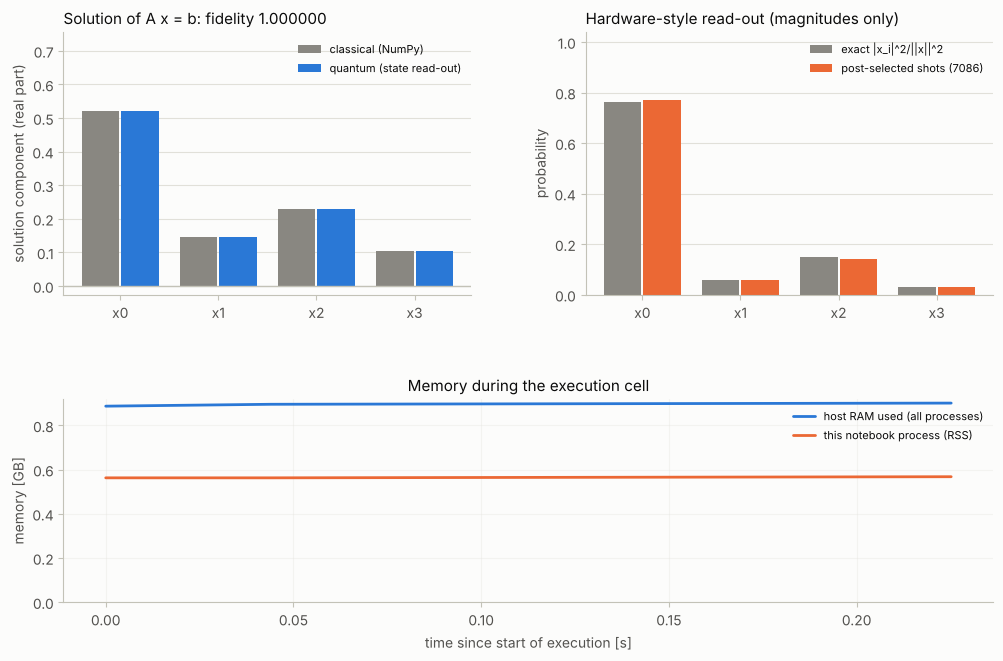

In [10]:
# ---------------------------------------------------------------------------------
# Section 9 - Quantum vs classical solution
# ---------------------------------------------------------------------------------
if not execution_ok:
    print("Skipped: the execution cell failed (see the error message above).")
else:
    d_out = x_classical.shape[0]
    exact_probs = np.abs(x_classical) ** 2 / np.sum(np.abs(x_classical) ** 2)
    # sampled probabilities for the original components (embedding/padding removed)
    sampled_full = np.zeros(2 ** n_b)
    for bits, c in post.items():
        sampled_full[int(bits, 2)] = c / max(accepted, 1)                    # system qubit 0 = most significant bit
    sampled = sampled_full[solution_slice]
    sampled = sampled / sampled.sum() if sampled.sum() > 0 else sampled
    print(f"{'i':>3} {'x classical':>22} {'x quantum (state)':>22} {'|x_i|^2 exact':>14} {'|x_i|^2 shots':>14}")
    for i in range(d_out):
        xc, xq = np.real_if_close(x_classical[i]), np.real_if_close(x_quantum[i])
        print(f"{i:>3} {str(np.round(xc, 6)):>22} {str(np.round(xq, 6)):>22} {exact_probs[i]:>14.4f} {sampled[i]:>14.4f}")
    stat_err = 1.0 / np.sqrt(max(accepted, 1))
    print(f"\nShot-based read-out: {accepted} accepted shots -> statistical error about +-{stat_err:.3f} per probability")

    fig = plt.figure(figsize=(12, 7.4))
    grid = fig.add_gridspec(2, 2, height_ratios=[1.1, 0.85], hspace=0.45, wspace=0.28)
    ax1 = fig.add_subplot(grid[0, 0])
    idx = np.arange(d_out)
    ax1.bar(idx - 0.2, np.real(x_classical), width=0.38, color=INK_MUTED, label="classical (NumPy)")
    ax1.bar(idx + 0.2, np.real(x_quantum), width=0.38, color=BLUE, label="quantum (state read-out)")
    ax1.axhline(0, color=AXIS_COLOR, linewidth=1)
    ax1.set_xticks(idx, [f"x{i}" for i in idx])
    ax1.set_ylabel("solution component (real part)")
    ax1.set_title(f"Solution of A x = b: fidelity {fidelity:.6f}", loc="left")
    ax1.legend(fontsize=8, loc="upper right")
    ax1.grid(axis="x", visible=False)
    span = max(np.max(np.abs(np.real(x_classical))), np.max(np.abs(np.real(x_quantum))))
    ax1.set_ylim(min(0, np.min(np.real(x_classical)), np.min(np.real(x_quantum))) * 1.2 - 0.05 * span, span * 1.45)
    ax2 = fig.add_subplot(grid[0, 1])
    ax2.bar(idx - 0.2, exact_probs, width=0.38, color=INK_MUTED, label="exact |x_i|^2/||x||^2")
    ax2.bar(idx + 0.2, sampled, width=0.38, color=ORANGE, label=f"post-selected shots ({accepted})")
    ax2.set_xticks(idx, [f"x{i}" for i in idx])
    ax2.set_ylabel("probability")
    ax2.set_ylim(0, max(exact_probs.max(), sampled.max()) * 1.35)
    ax2.set_title("Hardware-style read-out (magnitudes only)", loc="left")
    ax2.legend(fontsize=8, loc="upper right")
    ax2.grid(axis="x", visible=False)
    ax3 = fig.add_subplot(grid[1, :])
    monitor.plot(ax=ax3, title="Memory during the execution cell")
    plt.show()

---
## Section 10 - Final benchmark report

                                       FINAL BENCHMARK REPORT                                       
Algorithm                              : HHL (quantum linear systems)
Date (UTC)                             : 2026-11-05 11:59:01
CUDA-Q version                         : 0.16.0
Number of qubits                       : 7
Backend (requested -> used)            : auto -> cpu
CUDA-Q target                          : qpp-cpu
Simulation method                      : statevector
Numerical precision                    : fp64
Number of shots                        : 20000
Circuit construction time              : 0.0056 s
Compilation time (MLIR + JIT)          : 0.0524 s
Quantum execution time                 : 0.0018 s
Sampling run (execution)               : 0.0758 s
Total wall time of execution cell      : 0.1645 s
Timing method                          : CUDA-Q span tracer (first launch)
Peak host RAM used                     : 0.90 GB (5.3% of 16.9 GB)
Peak notebook process RSS            

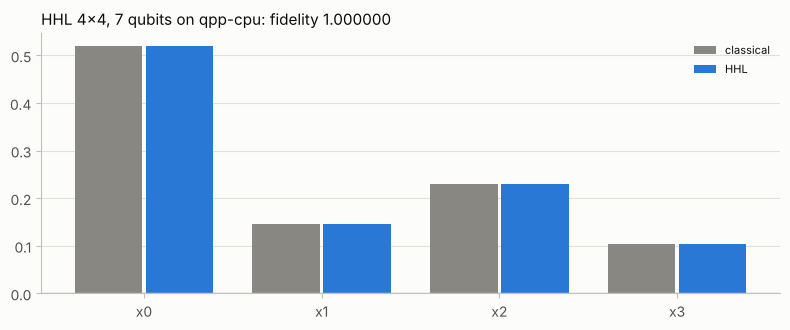

In [11]:
# ---------------------------------------------------------------------------------
# Section 10 - Final benchmark report
# ---------------------------------------------------------------------------------
if not execution_ok:
    print(f"No report: execution failed with {type(execution_error).__name__}: {execution_error}")
else:
    report = build_report("HHL (quantum linear systems)", backend_cfg, total_qubits, SHOTS, phases, memory,
                          extra_times={"Sampling run (execution)": sampling_time})
    report["System"] = f"{x_classical.shape[0]}x{x_classical.shape[0]} matrix, kappa = {kappa:.3f}" + (f" ({'; '.join(notes)})" if notes else "")
    report["Registers"] = f"{n_c} clock + {n_b} system + 1 ancilla = {total_qubits} qubits; t = {t_evolution:.5f}, C = {C_constant:.5f}"
    report["Expected result"] = f"x = {np.round(np.real_if_close(x_classical), 6).tolist()} (NumPy), P_success = {p_success_ideal:.4f}"
    report["Actual result"] = f"x = {np.round(np.real_if_close(x_quantum), 6).tolist()} (state read-out), P_success = {p_success_state:.4f} (shots: {p_success_shots:.4f})"
    report["Fidelity of |x>"] = f"{fidelity:.10f}"
    report["Relative error ||x_q - x_c|| / ||x_c||"] = f"{relative_error:.3e}"
    report["Shot read-out max |error| of |x_i|^2"] = f"{np.max(np.abs(sampled - exact_probs)):.4f} (statistical scale {stat_err:.3f})"
    final_fig, ax = plt.subplots(figsize=(8, 3.4))
    ax.bar(idx - 0.2, np.real(x_classical), width=0.38, color=INK_MUTED, label="classical")
    ax.bar(idx + 0.2, np.real(x_quantum), width=0.38, color=BLUE, label="HHL")
    ax.axhline(0, color=AXIS_COLOR, linewidth=1)
    ax.set_xticks(idx, [f"x{i}" for i in idx])
    ax.set_title(f"HHL {x_classical.shape[0]}x{x_classical.shape[0]}, {total_qubits} qubits on {cudaq.get_target().name}: fidelity {fidelity:.6f}", loc="left")
    ax.legend(fontsize=8)
    ax.grid(axis="x", visible=False)
    final_fig.tight_layout()
    show_report(report, save=SAVE_REPORT, out_dir=EXPORT_DIR, name="hhl_benchmark_report", figure=final_fig)
    plt.show()

---
### Things to try next
* `NUM_CLOCK_QUBITS = 3`: the eigenvalue 4 no longer fits ($\kappa = 4 > 3$ levels), the time $t$ is rescaled and the
  fidelity drops - phase-estimation precision limits HHL.
* `MATRIX_A = "random"`, `RANDOM_CONDITION_NUMBER = 20`: the success probability falls roughly like $1/\kappa^2$ and more
  clock qubits are needed.
* `MATRIX_A = [[1, 2], [0, 1]]`: a non-Hermitian matrix is embedded automatically (one extra system qubit).